In [1]:
import os, shutil, imageio_ffmpeg

src = imageio_ffmpeg.get_ffmpeg_exe()
dst_dir = os.path.abspath("../ffmpeg_bin")
os.makedirs(dst_dir, exist_ok=True)
shutil.copy(src, os.path.join(dst_dir, "ffmpeg.exe"))
os.environ["PATH"] = dst_dir + os.pathsep + os.environ["PATH"]

In [2]:
import subprocess
print(subprocess.run(["ffmpeg", "-version"], capture_output=True, text=True).stdout[:50])

ffmpeg version 9.0.2-essentials_build-www.gyan.dev


In [3]:
import time
import torch
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
if not (project_root / "src").exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))
from src.asr import load_asr, transcribe, load_audio

device = 0 if torch.cuda.is_available() else -1

asr_tiny, _ = load_asr("tiny")

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

In [4]:
audio_dir = Path("../data/my_recordings")

for file in sorted(audio_dir.glob("*.ogg")):
    wav = file.with_suffix(".wav")
    if not wav.exists():
        subprocess.run(
            ["ffmpeg", "-y", "-i", str(file), "-ar", "16000", "-ac", "1", str(wav)],
            check=True
        )
files = sorted(audio_dir.glob("*.wav"))
print(f"Found {len(files)} audio files in {audio_dir}")
for file in files:
    print(file.name)


Found 6 audio files in ..\data\my_recordings
18_37_wake_up.wav
5_min_timer.wav
run_browser.wav
sound_lower.wav
sound_upper.wav
weather.wav


In [5]:
for file in files:
    start = time.time()
    text = transcribe(asr_tiny, load_audio(file), language="russian")
    elapsed = time.time() - start
    print(f"{file.name:25} | {elapsed:4.1f} с | {text}")

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


18_37_wake_up.wav         |  3.3 с | Разбудем меня в 1837.
5_min_timer.wav           |  1.6 с | Вставь таймер на 5 минут.
run_browser.wav           |  1.7 с | Запусти бралвер.
sound_lower.wav           |  1.5 с | Сделай звук потюже.
sound_upper.wav           |  1.4 с | Делый зуб по громче.
weather.wav               |  1.4 с | Какая сегодня порбона.


In [6]:
asr_base , _ = load_asr("base")


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

In [7]:
for file in files:
    start = time.time()
    text = transcribe(asr_base, load_audio(file), language="russian")
    elapsed = time.time() - start
    print(f"{file.name:25} | {elapsed:4.1f} с | {text}")

18_37_wake_up.wav         |  4.4 с | Разбудем меня 1837.
5_min_timer.wav           |  4.6 с | Ставь таймер на 5 минут.
run_browser.wav           |  4.8 с | Запусти браузер.
sound_lower.wav           |  4.7 с | Сделай звук потиши.
sound_upper.wav           |  5.6 с | Делай зуб по громче.
weather.wav               |  3.5 с | Какая сегодня погода?


In [8]:
asr_small , _ = load_asr("small")

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

In [9]:
for file in files:
    start = time.time()
    text = transcribe(asr_small, load_audio(file), language="russian")
    elapsed = time.time() - start
    print(f"{file.name:25} | {elapsed:4.1f} с | {text}")

18_37_wake_up.wav         | 15.7 с | Разбуди меня в 1837.
5_min_timer.wav           | 14.9 с | Поставь таймер на 5 минут.
run_browser.wav           | 15.8 с | Запусти браузер.
sound_lower.wav           | 14.3 с | Сделаю звук потише.
sound_upper.wav           | 14.4 с | Делаю звук погромче.
weather.wav               | 11.9 с | Какая сегодня погода?


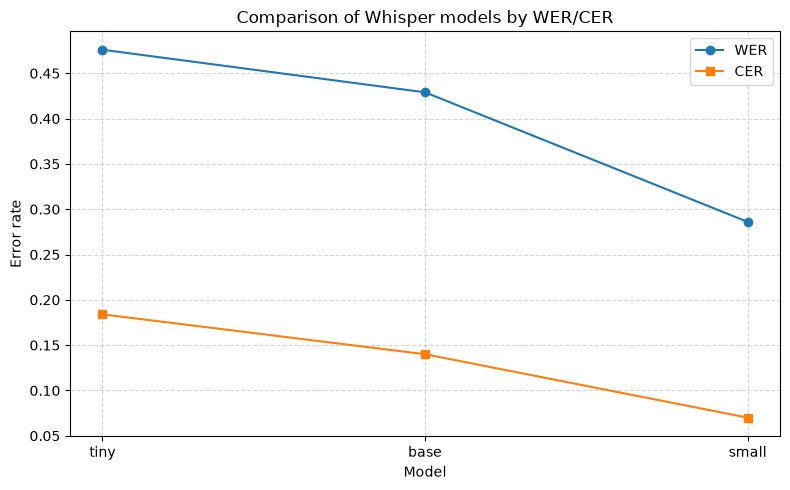

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

summary = pd.read_csv("../results/summary.csv")

plt.figure(figsize=(8, 5))
plt.plot(summary["model"], summary["WER"], marker="o", label="WER")
plt.plot(summary["model"], summary["CER"], marker="s", label="CER")
plt.title("Comparison of Whisper models by WER/CER")
plt.xlabel("Model")
plt.ylabel("Error rate")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../results/wer_cer.png", dpi=150, bbox_inches="tight")
plt.show()

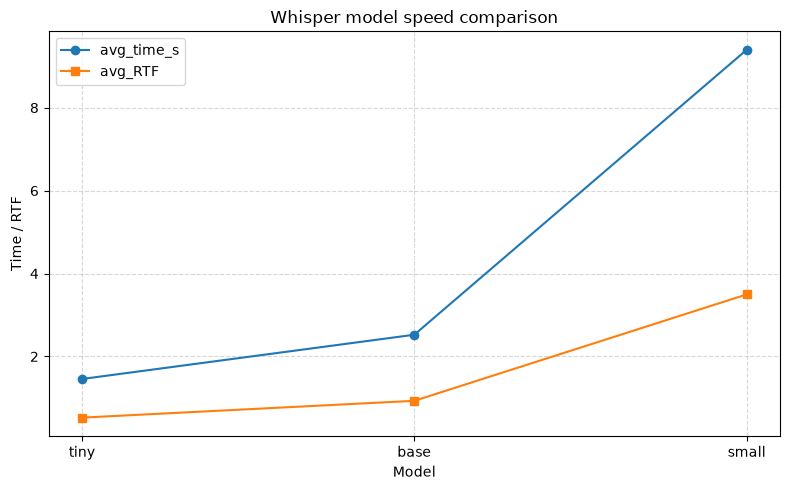

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(summary["model"], summary["avg_time_s"], marker="o", label="avg_time_s")
plt.plot(summary["model"], summary["avg_RTF"], marker="s", label="avg_RTF")
plt.title("Whisper model speed comparison")
plt.xlabel("Model")
plt.ylabel("Time / RTF")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../results/speed_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

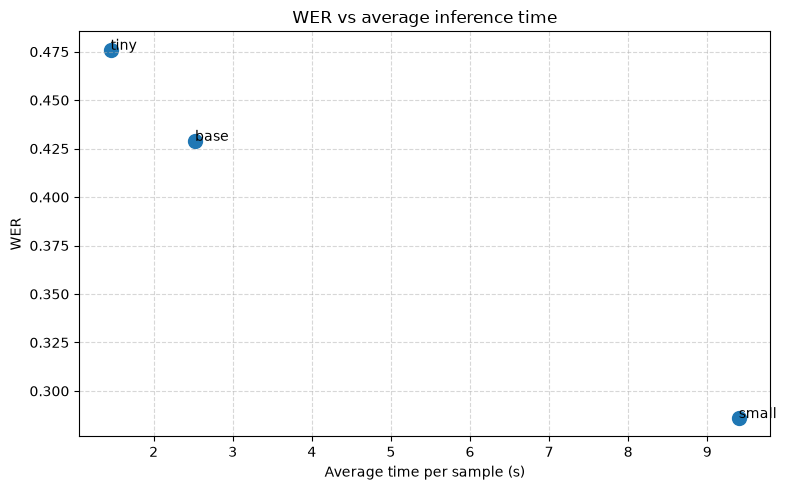

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(summary["avg_time_s"], summary["WER"], s=100)
for _, row in summary.iterrows():
    plt.text(row["avg_time_s"], row["WER"], row["model"], fontsize=10)

plt.title("WER vs average inference time")
plt.xlabel("Average time per sample (s)")
plt.ylabel("WER")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("../results/wer_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()